<a href="https://colab.research.google.com/github/abuebayyeh/imperial_eee_machine_learning_course/blob/main/04_ML_Logistic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Logistic Regression


---

Despite of the efficiency of the perceptron algorithm in binary classification tasks; however, the algorithm never converges when the data are not linearly seperable. Logistic regression is a supervised ML algorithm that is used in binary classification problems. The algorithm converts the linear model predictions into a probability between 0 and 1. For better understanding of this algorithm, let us recall the odds ratio, which is the odds in favour of a particular event to occur. The odds ratio can be formulated as $\frac{p}{1-p}$, where $p$ is the probability of a positive event (the event that we want to predict e.g. $y = 1$). Let us now extend our previous discussion and define the logit function, which is simply the logarithm of the odds ratio (log-odds) given by the following equation:

\begin{equation}
logit(p) = \log \left(\frac{p}{1-p}\right)
\end{equation}

As $p$ is a probability, the logit function takes a value between 0 and 1 and transforms them to values over the entire real number range, which we can use to express a linear relationship between feature values and the log-odds.

\begin{equation}
logit\left(p\left(y=1|\mathbf{x}\right)\right)=w_0x_0 + w_1x_1 + \ldots + w_nx_n = \sum_{i=0}^{n} w_nx_n
\end{equation}

Hence, $p\left(y=1|\mathbf{x}\right)$ is the probability of a sample point that belongs to class 1 given its features $x$. However, in the learning process, we are more interested in the opposite case such that predicting the probability that a certain sample belongs to a particular class, which is simply the inverse of the logit function. The inverse of the logit function is called the $logistic$ function (also know as $Sigmoid$ function). The Sigmoid function is given by the equation below:

\begin{equation}
\sigma(z) = \frac{1}{1+e^{-z}}
\end{equation}

Hence, $z$ is the net input, that is, the linear combination of weights and sample features such that $z = \sum_{i=0}^{n} w_nx_n$. The Sigmoid function can be further visualised and plotted using the figure below:

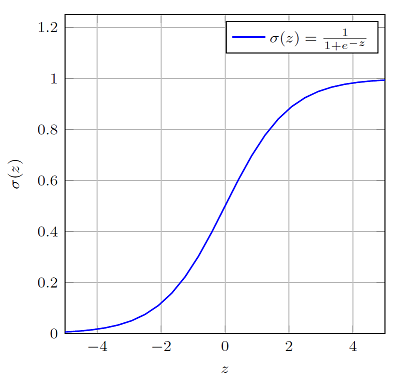

From the figure above we can observe that the Sigmoid function is bouned between 0 and 1. Such that if $z$ goes toward infinity ($z \to \infty$) then $\sigma(z)=\frac{1}{1+e^{-\infty}}=1$, and on the other hand when $z$ goes toward minus infinity ($z \to -\infty$) then $\sigma(z)=\frac{1}{1+e^{\infty}}=0$. Thus, we conclude that sigmoid function takes real number values as input and transforms them to values in the range [0,1] with $\sigma(0) = 0.5$.

In logistic regression, the activation function simply becomes the sigmoid function that we defined earlier, which is illustrated in the following figure:

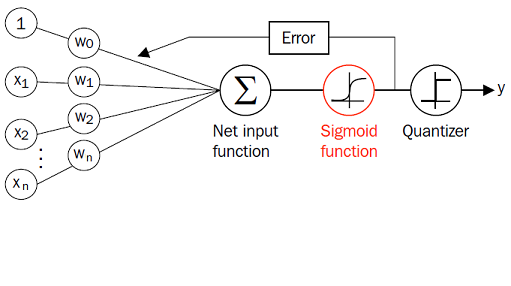

The output of the Sigmoid activation function is interpreted as the probability of particular sample belonging to class 1 $\sigma(z)=p\left(y=1|\mathbf{x,w}\right)$ given set of features $x$ and set of weights $w$. For instance, assume we have a binary classifier to classify samples of Iris-Versicolor ($y=1$) vs. Iris-Setosa ($y=0$). Then if we compute $\sigma(z)=0.9$, it means that the chance that this sample is an Iris-Versicolor flower is $90\%$. Similarly, the probability that this flower is an Iris-Setosa flower can be calculated as $p\left(y=0|\mathbf{x,w}\right) = 1 - p\left(y=1|\mathbf{x,w}\right) = 0.1$ or $10\%$.


So far we have discussed how Logistic regression makes predictions, but we did not talk about the cost function and learning process. Unlike the case in linear regression where we used MSE cost function, in logistic regression we use log-loss (also known as binary cross entropy (BCE)), given by the equation below:

\begin{equation}
    J(w)=\frac{1}{N} \sum_{i=1}^{N} [-y_{i}\cdot\log\left(\hat{y}_{i}\right)-\left(1-y_{i}\right)\cdot\log\left(1-\hat{y}_{i}\right)]
\end{equation}
where $y_{i}$ is the label  for training example $i$, $\hat{y}_{i}$ is the predicted class by applying the hypothesis or $\sigma(z)$.


For more information why we chose BCE over MSE, please refer to the lecture notes

Our main aim is to minimise our BCE cost function in order to get accurate predictions. In order to do that, we keep updating the parameter $w$ in the direction that minimises the cost function. The amount of change that we modify $w$ is called the gradient and is given by differentiating the cost function with respect to $w$. We can control how fast this gradient step is moving by introducing the learning rate ($\alpha$). This process is called Gradient Descent and is illustrated in the figure below:

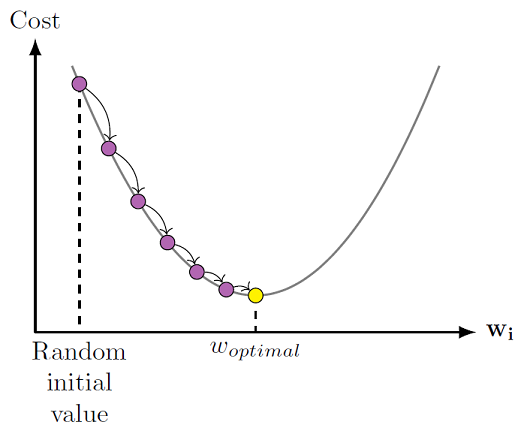


When the training is done and we want to predict the output using test data, the predicted probability can be converted into a binary outcome via a quantizer (unit step function) such that:

\begin{equation}
y_{pred} = \begin{cases}
      1 & \hat{y}\geq 0.5 \\
      0 & otherwise
   \end{cases}
\end{equation}


Reference:
"Python Machine Learning," Sebastian Raschka, Packt Publishing, 2015


# Data Used & Problem Definition

We will use logistic regression as a binary classifier between Setosa vs other classes (verginica and versicolor grouped together). Here we say that data points with features that result in output probabilities closer to 0 are likely Setosa, while values closer to 1 are likely not Setosa. For simplicity, we will consider two features, petal length and sepal length, which can be visualised in a 2D plot.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
import pandas as pd

In [2]:
iris = datasets.load_iris()

In [3]:
iris_data = pd.DataFrame(data=iris['data'],columns=iris['feature_names'])
iris_data["target"] = iris['target']

In [4]:
iris_data

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [5]:
iris.target_names

array(['setosa', 'versicolor', 'virginica'], dtype='<U10')

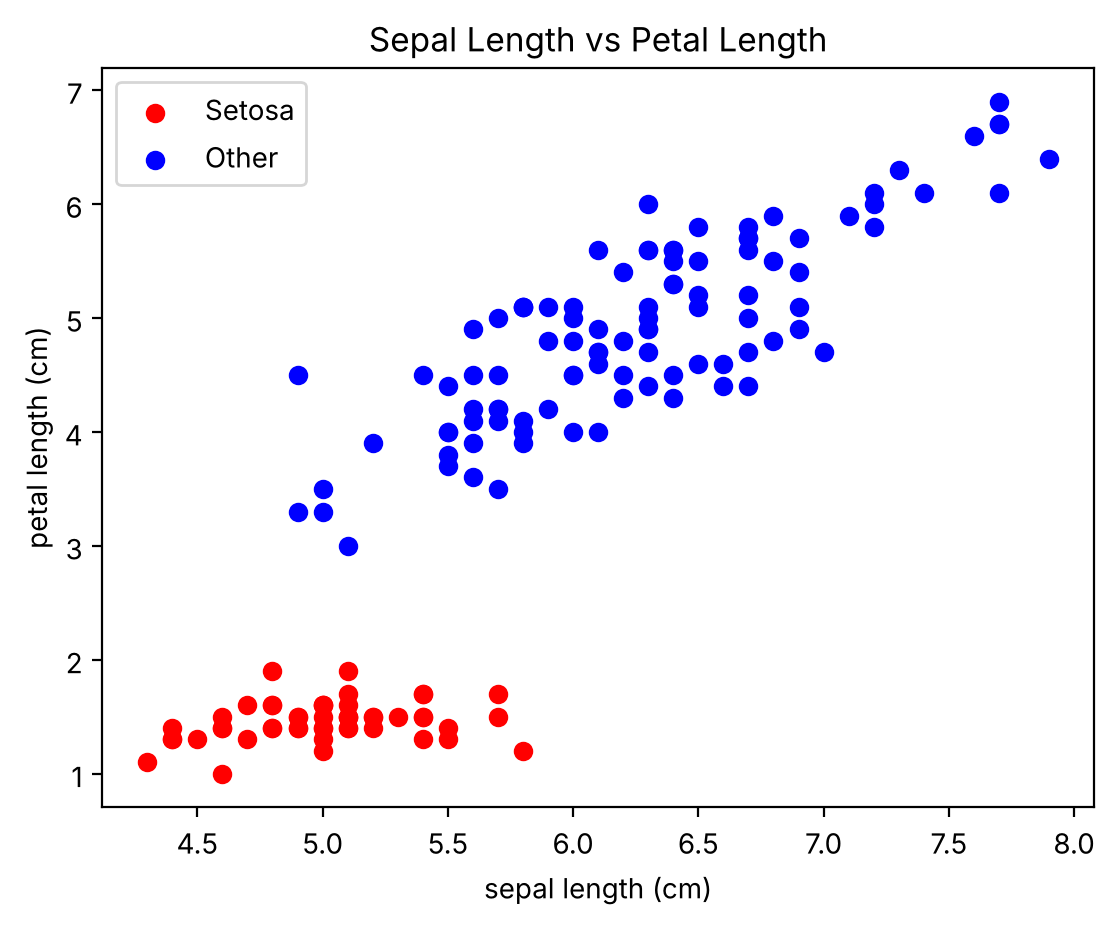

In [6]:
# Target labels are the index in iris.target_names
labels = iris_data.iloc[:,4]

# Setosa is assigned label 0, while all other classes will have a label of 1
y = np.where(labels == 0, 0, 1)

# Consider only two features - sepal length (column 0) and petal length (column 2)
# Bias term (intercept) is added to each data point (row)
X = iris_data.iloc[:,[0,2]]
intercept = np.ones((X.shape[0], 1))
X = np.concatenate((intercept, X), axis=1)

# Plot features in 2D plot - sepal length (x-axis) vs petal length (y-axis)
feat1, feat2 = 'sepal length (cm)', 'petal length (cm)'
X_target = iris_data[iris_data.target==0]
X_other = iris_data[iris_data.target!=0]

plt.scatter(X_target[feat1],X_target[feat2],color='red',marker='o',label="Setosa")
plt.scatter(X_other[feat1],X_other[feat2],color='blue',marker='o',label='Other')
plt.title("Sepal Length vs Petal Length")
plt.xlabel(feat1)
plt.ylabel(feat2)
plt.legend(loc='upper left')
plt.show()

In [7]:
def sigmoid(z):
    # Sigmoid function
    return 1 / (1 + np.exp(-z))

In [8]:
def cost(Y, y):
    # log-loss or Binary Cross Entropy (BCE)
    eps = 1e-15 # to avoid numerical error at log(0)
    return (-y * np.log(Y+eps) - (1 - y) * np.log(1 - Y + eps)).mean()

In [9]:
def plot_cost(loss):
    # Function for plotting the cost vs iterations.
    plt.plot(range(1, len(loss) + 1), loss)
    plt.xlabel('Iterations')
    plt.ylabel('Cost')
    # plt.savefig('plot.pdf')
    plt.show()

In [10]:
def predict(X, W):
    # Function for predicting on test data (see Task 1)
    prediction = sigmoid(np.dot(X, W))
    return prediction.round()

In [11]:
def fit(alpha, num_iter, X, y):
    # weights initialization
    W = np.zeros(X.shape[1])
    loss_list = []
    for i in range(num_iter):
        # Feed forward
        z = np.dot(X, W)
        Y = sigmoid(z)
        # Gradient
        W += alpha * (np.dot(X.T, (y-Y)) / y.size)
        loss = cost(Y, y)
        loss_list.append(loss)

        if i % 100 == 0:
            print(f'iteration: {i+1} \t', f'cost: {loss} \t', f'weights: {W} \t')
    plot_cost(loss_list)
    # This function will return the final weights as an array
    return W

iteration: 1 	 cost: 0.6931471805599433 	 weights: [0.00166667 0.01253    0.01391667] 	
iteration: 101 	 cost: 0.3971690488847863 	 weights: [-0.05071148 -0.07762237  0.42536019] 	
iteration: 201 	 cost: 0.29984517309777964 	 weights: [-0.10551432 -0.23097319  0.68989714] 	
iteration: 301 	 cost: 0.23820942493735064 	 weights: [-0.14864573 -0.34969591  0.90262115] 	
iteration: 401 	 cost: 0.196815362215292 	 weights: [-0.18374873 -0.44513976  1.07818086] 	
iteration: 501 	 cost: 0.1674853678274872 	 weights: [-0.21316007 -0.52436457  1.22669262] 	
iteration: 601 	 cost: 0.14576052746256243 	 weights: [-0.23838792 -0.5918273   1.3549739 ] 	
iteration: 701 	 cost: 0.12908024748143987 	 weights: [-0.26043675 -0.65044743  1.46769223] 	
iteration: 801 	 cost: 0.11589461609963034 	 weights: [-0.27999968 -0.70221333  1.56813002] 	
iteration: 901 	 cost: 0.10521991405430549 	 weights: [-0.29757115 -0.74852835  1.65866121] 	
iteration: 1001 	 cost: 0.09640551861790733 	 weights: [-0.31351439 -0

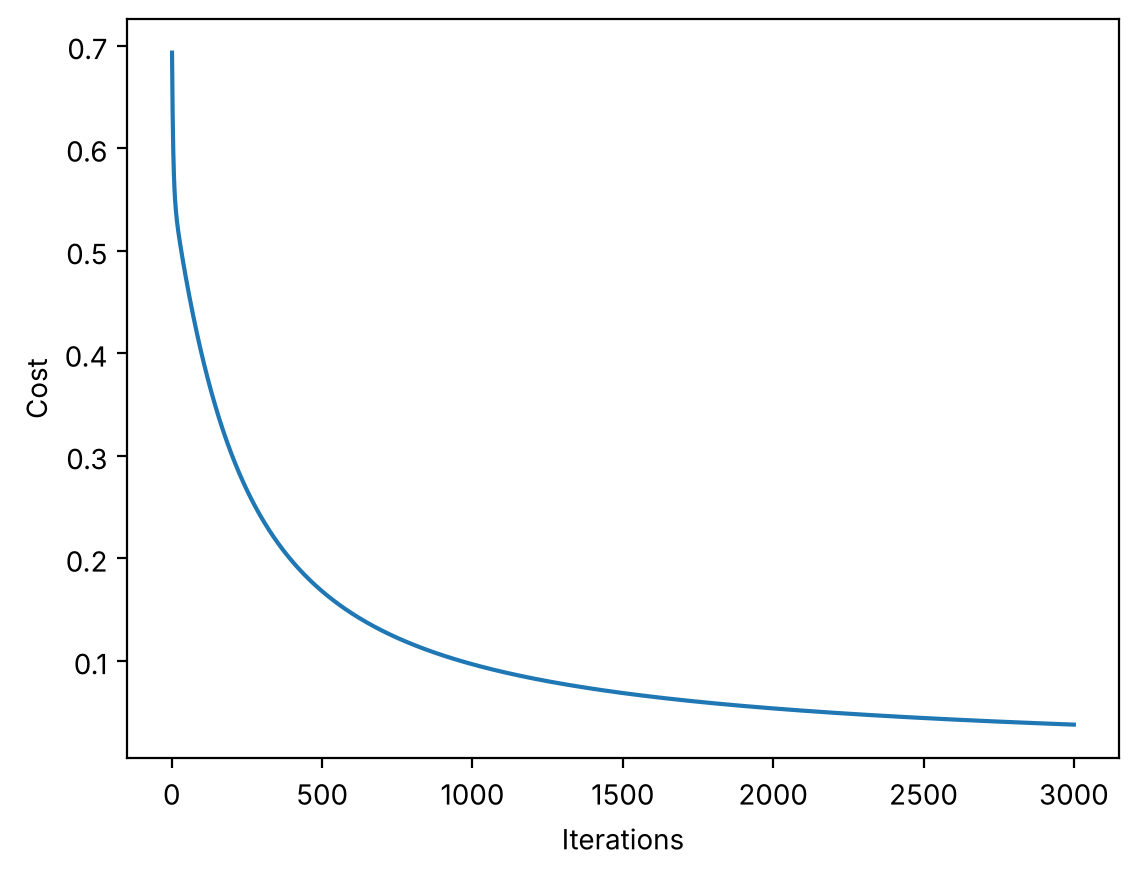

In [12]:
alpha = 0.01
num_iter = 3000
model_weights = fit(alpha, num_iter, X,y)

In [13]:
predictions = predict(X, model_weights)
pred = predictions.astype('int')
true = y.astype('int')

# Evaluation Metrics

Evaluation metrics are used to measure the performance of machine learning models. It is very important to evaluate the model after training takes place to decide whether the model can be implemented in the project or not. There are a variety of techniques used for evaluation such as classification accuracy, loss and confusion matrix. Confusion matrix is very useful tool for evaluation. It visualises the predictions for a classification problem against the real labels in table format.  Each row of the matrix represents the instances of real labels while each column represents the instances of predicted labels. The values of the confusion matrix are denoted by four categories, namely, true positive (TP), true negative (TN), false negative (FN) and false positive (FP). The outcomes of a confusion matrix can be visualised in Figure


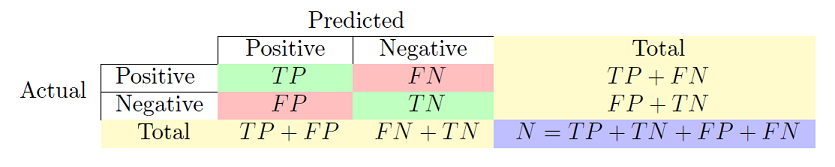

In [14]:
def compute_confusion_matrix(true, pred):

    num_cls = len(np.unique(true)) # Number of classes
    result = np.zeros((num_cls, num_cls))

    for i in range(len(true)):
        result[true[i]][pred[i]] += 1

    return result

conf_matrix = compute_confusion_matrix(true, pred)
print('Confusion matrix result: ')
print(conf_matrix)

diagonal_sum = conf_matrix.trace()
sum_of_all_elements = conf_matrix.sum()
accuracy = diagonal_sum / sum_of_all_elements
print('accuracy = {:0.2f}%'.format(accuracy*100))

Confusion matrix result: 
[[ 50.   0.]
 [  0. 100.]]
accuracy = 100.00%


## Task 1 [40 marks]

In the provided code, the network's performance was assessed using the same training dataset for both training and evaluation, which is not a recommended practice in evaluating machine learning algorithms. Your task is to adjust the code to split the data into two separate sets: a training set and a testing set. The training set should account for 80% of the original data, while the remaining 20% will constitute the test data. Additionally, you should address the following points:

1. Discuss the significance of using two distinct datasets (training and testing) when evaluating a machine learning algorithm.

2. Provide the code you used to divide the original dataset into the training and testing datasets. Ensure that the split is random and maintains data integrity.

3. After modifying the code and training the model on the training dataset, calculate the confusion matrix and total accuracy of the algorithm using the testing dataset. Include these performance metrics to assess the model's effectiveness in classifying data.



### Task 1.1 – Why use separate training and test sets?

If a model is evaluated on the same data it was trained on, the score only shows how well it has **memorised** those samples, not how well it will do on new data. A model can fit the training set perfectly, noise included, and still fail on new samples. That is overfitting, and the training accuracy hides it completely.

Holding back a test set the model never sees during training gives an **unbiased estimate of generalisation performance**, which is what matters when the model is used in practice. The test set must stay untouched until the final evaluation, so that no information from it leaks into training (for example through choosing hyper-parameters). Otherwise the estimate becomes optimistic again.

In [15]:

# Task 1
# Task 1.2 - random 80/20 train/test split written with numpy only.
# The split is *stratified*: each class is shuffled and split 80/20 separately, so the
# train and test sets keep the same class proportions as the full dataset.
# The same index is used for X and y, so every feature row stays with its own label.

def train_test_split_np(X, y, test_ratio=0.2, seed=42):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n_test = int(round(test_ratio * len(idx)))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    train_idx = rng.permutation(train_idx)
    test_idx = rng.permutation(test_idx)
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

X_train, X_test, y_train, y_test = train_test_split_np(X, y, test_ratio=0.2, seed=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Class balance (fraction of label 1) - full: %.3f, train: %.3f, test: %.3f"
      % (y.mean(), y_train.mean(), y_test.mean()))

Train: (120, 3) | Test: (30, 3)
Class balance (fraction of label 1) - full: 0.667, train: 0.667, test: 0.667


iteration: 1 	 cost: 0.6931471805599435 	 weights: [0.00166667 0.012625   0.0140625 ] 	
iteration: 101 	 cost: 0.39333214147735224 	 weights: [-0.05196518 -0.07881813  0.42768714] 	
iteration: 201 	 cost: 0.29548112802807264 	 weights: [-0.10769514 -0.23293035  0.69253847] 	
iteration: 301 	 cost: 0.23394162871805152 	 weights: [-0.15152371 -0.35188716  0.90474094] 	
iteration: 401 	 cost: 0.192849084286756 	 weights: [-0.18718459 -0.44729373  1.07933844] 	
iteration: 501 	 cost: 0.16386494840786844 	 weights: [-0.21706542 -0.52633996  1.22667977] 	
iteration: 601 	 cost: 0.1424736235994173 	 weights: [-0.24270301 -0.5935488   1.35370676] 	
iteration: 701 	 cost: 0.12609693165057517 	 weights: [-0.26511883 -0.65187467  1.46515239] 	
iteration: 801 	 cost: 0.11318177622373113 	 weights: [-0.28501668 -0.70332536  1.56433334] 	
iteration: 901 	 cost: 0.10274634230963749 	 weights: [-0.30289808 -0.74931552  1.65364121] 	
iteration: 1001 	 cost: 0.0941434483154278 	 weights: [-0.31913118 -0

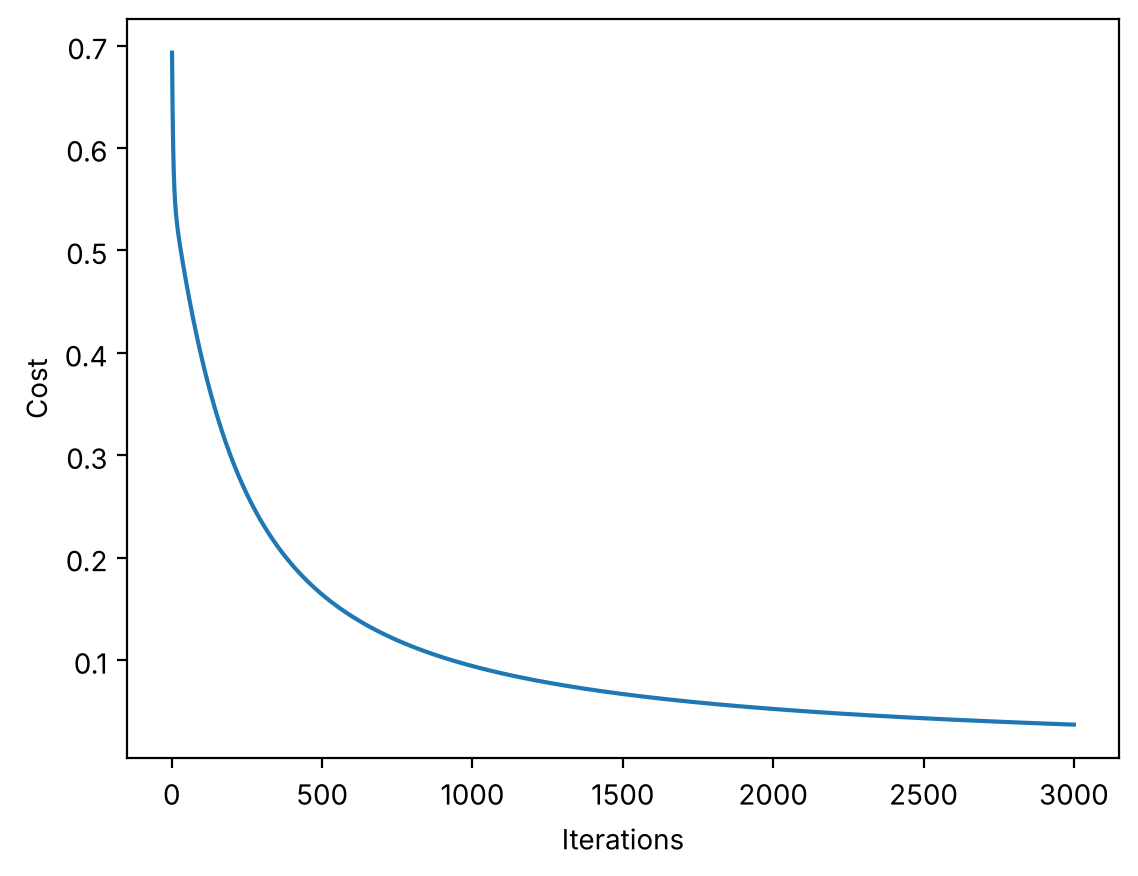

Final weights: [-0.4983184  -1.23974951  2.63757551]


In [16]:
# Task 1.3 - train on the training set only
alpha = 0.01
num_iter = 3000
model_weights = fit(alpha, num_iter, X_train, y_train)
print("Final weights:", model_weights)

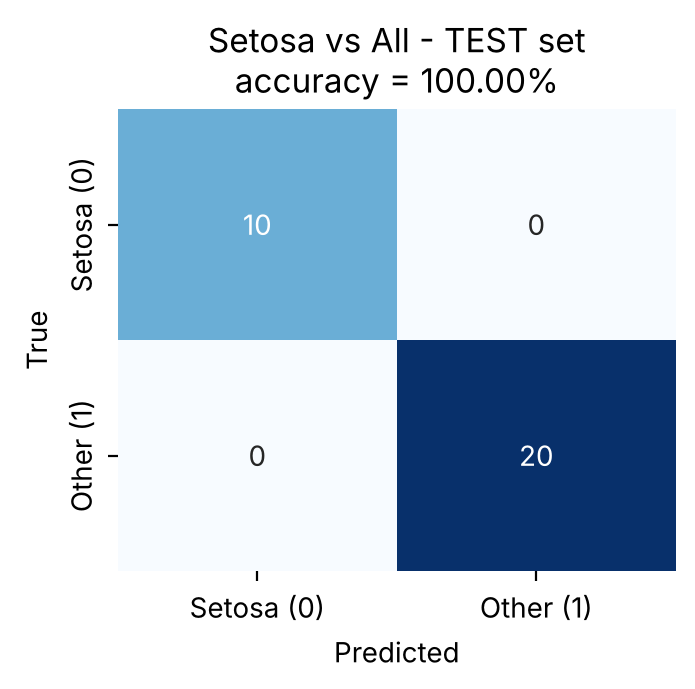

Test confusion matrix:
 [[10.  0.]
 [ 0. 20.]]
Test accuracy = 100.00%


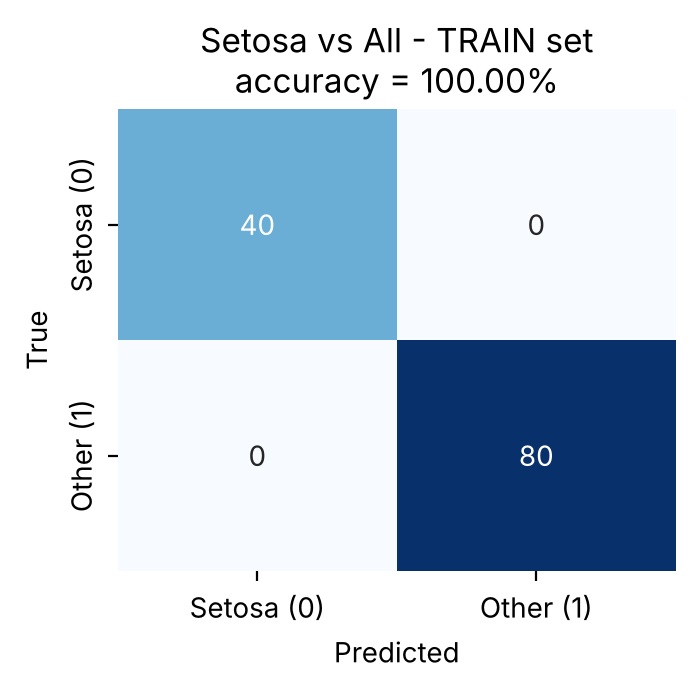

Train accuracy = 100.00%


In [17]:
# Task 1.3 (continued) - evaluate on the unseen test set

def evaluate(X_eval, y_eval, W, title="Confusion matrix", class_names=("0", "1")):
    pred = predict(X_eval, W).astype('int')
    true = y_eval.astype('int')
    cm = np.zeros((2, 2))
    for t, p in zip(true, pred):
        cm[t][p] += 1
    acc = cm.trace() / cm.sum()
    plt.figure(figsize=(3.6, 3))
    sns.heatmap(cm, annot=True, fmt='.0f', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('True')
    plt.title(f"{title}\naccuracy = {acc * 100:.2f}%")
    plt.show()
    return cm, acc

cm_test, acc_test = evaluate(X_test, y_test, model_weights,
                             "Setosa vs All - TEST set", ("Setosa (0)", "Other (1)"))
print("Test confusion matrix:\n", cm_test)
print("Test accuracy = {:0.2f}%".format(acc_test * 100))

cm_train, acc_train = evaluate(X_train, y_train, model_weights,
                               "Setosa vs All - TRAIN set", ("Setosa (0)", "Other (1)"))
print("Train accuracy = {:0.2f}%".format(acc_train * 100))

**Task 1 notes.** The model is trained on 120 samples and tested on 30 samples it has never seen. Setosa is linearly separable from the other two species using sepal and petal length, so the classifier also gets 100% on the test set. With a strictly separate test set, this figure is now a fair estimate of performance on new flowers rather than a memorisation score.

## Task 2 [20 marks]

In the provided code, the primary objective was to classify Iris-Setosa versus other classes. Your task is to modify the code so that it can classify Iris-Versicolor versus other classes and Iris-Virginica versus other classes separately. For each case, you should divide the dataset into training and testing subsets. Additionally, you should cover the following aspects:

1. Provide the code you used to adjust the dataset for each classification scenario, ensuring that you have separate training and testing data for Iris-Versicolor versus other classes and Iris-Virginica versus other classes.

2. Present the final weights obtained for each classification case.

3. Compare the performance of the network for each classification case. Discuss any differences in performance and provide justifications for why the performance may vary between the two cases. Consider factors such as dataset characteristics and class separability.

Ensure that your code modifications are clearly documented, and you provide logical explanations for the observed differences in classification performance.


In [18]:
# Task 2
# The only change to the data preparation is which original class is mapped to label 1.
# Target index in iris.target_names: 0 = setosa, 1 = versicolor, 2 = virginica.

def make_one_vs_rest(target_class):
    labels = iris_data.iloc[:, 4].values
    y_ovr = np.where(labels == target_class, 1, 0)      # chosen class -> 1, others -> 0
    X_ovr = iris_data.iloc[:, [0, 2]].values               # sepal length, petal length
    X_ovr = np.concatenate((np.ones((X_ovr.shape[0], 1)), X_ovr), axis=1)   # bias column
    return X_ovr, y_ovr

def plot_one_vs_rest(target_class):
    name = iris.target_names[target_class].capitalize()
    tgt = iris_data[iris_data.target == target_class]
    oth = iris_data[iris_data.target != target_class]
    plt.scatter(oth[feat1], oth[feat2], color='blue', label='Other')
    plt.scatter(tgt[feat1], tgt[feat2], color='red', label=name)
    plt.title(f"{name} vs Other"); plt.xlabel(feat1); plt.ylabel(feat2)
    plt.legend(loc='upper left'); plt.show()

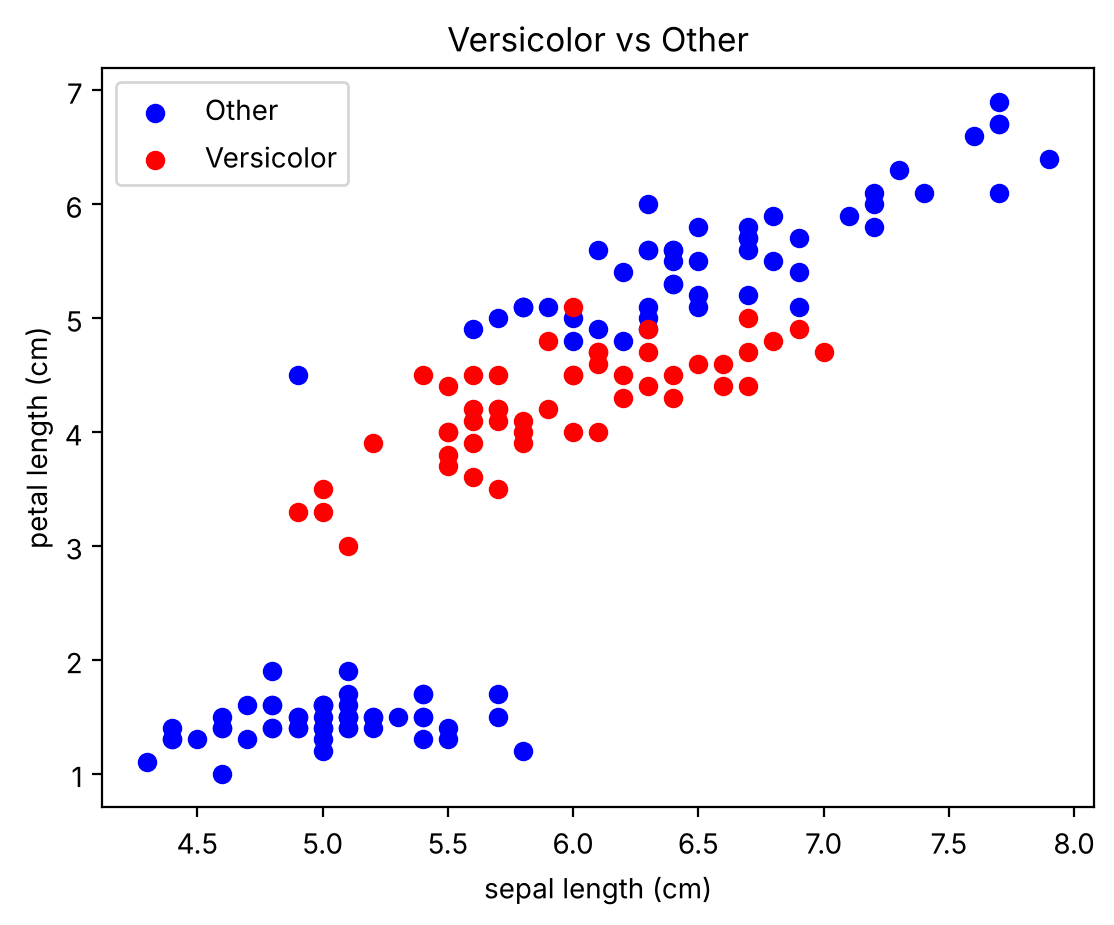

Train: (120, 3) Test: (30, 3)
iteration: 1 	 cost: 0.6931471805599435 	 weights: [-0.00166667 -0.00950417 -0.00452917] 	
iteration: 101 	 cost: 0.6292246761438516 	 weights: [-0.03116063 -0.14663361  0.07133517] 	
iteration: 201 	 cost: 0.617677290566674 	 weights: [-0.04411889 -0.20533705  0.15974188] 	


iteration: 301 	 cost: 0.6108885975379403 	 weights: [-0.05234562 -0.25098105  0.22736967] 	
iteration: 401 	 cost: 0.6067951715307359 	 weights: [-0.05706104 -0.28689935  0.27976337] 	
iteration: 501 	 cost: 0.6042685352013789 	 weights: [-0.0591355  -0.31547924  0.32080929] 	
iteration: 601 	 cost: 0.6026746963715637 	 weights: [-0.05919775 -0.33845083  0.35327243] 	
iteration: 701 	 cost: 0.6016477845037094 	 weights: [-0.05770914 -0.35708699  0.37915597] 	
iteration: 801 	 cost: 0.6009714651223315 	 weights: [-0.05501359 -0.37233851  0.39993735] 	
iteration: 901 	 cost: 0.6005151001506751 	 weights: [-0.05137118 -0.38492568  0.41672417] 	
iteration: 1001 	 cost: 0.6001983818056107 	 weights: [-0.04698117 -0.39540096  0.43035875] 	
iteration: 1101 	 cost: 0.5999712008168203 	 weights: [-0.04199787 -0.40419266  0.44148952] 	
iteration: 1201 	 cost: 0.5998019017874171 	 weights: [-0.03654188 -0.41163584  0.4506209 ] 	
iteration: 1301 	 cost: 0.5996702819344976 	 weights: [-0.03070824 

iteration: 2601 	 cost: 0.5987701055150834 	 weights: [ 0.05902459 -0.4589582   0.49474379] 	
iteration: 2701 	 cost: 0.5987125972046622 	 weights: [ 0.06627868 -0.46089996  0.49579886] 	
iteration: 2801 	 cost: 0.5986553372533128 	 weights: [ 0.07353956 -0.46279016  0.4967809 ] 	
iteration: 2901 	 cost: 0.5985982987829526 	 weights: [ 0.08080402 -0.4646378   0.49770308] 	


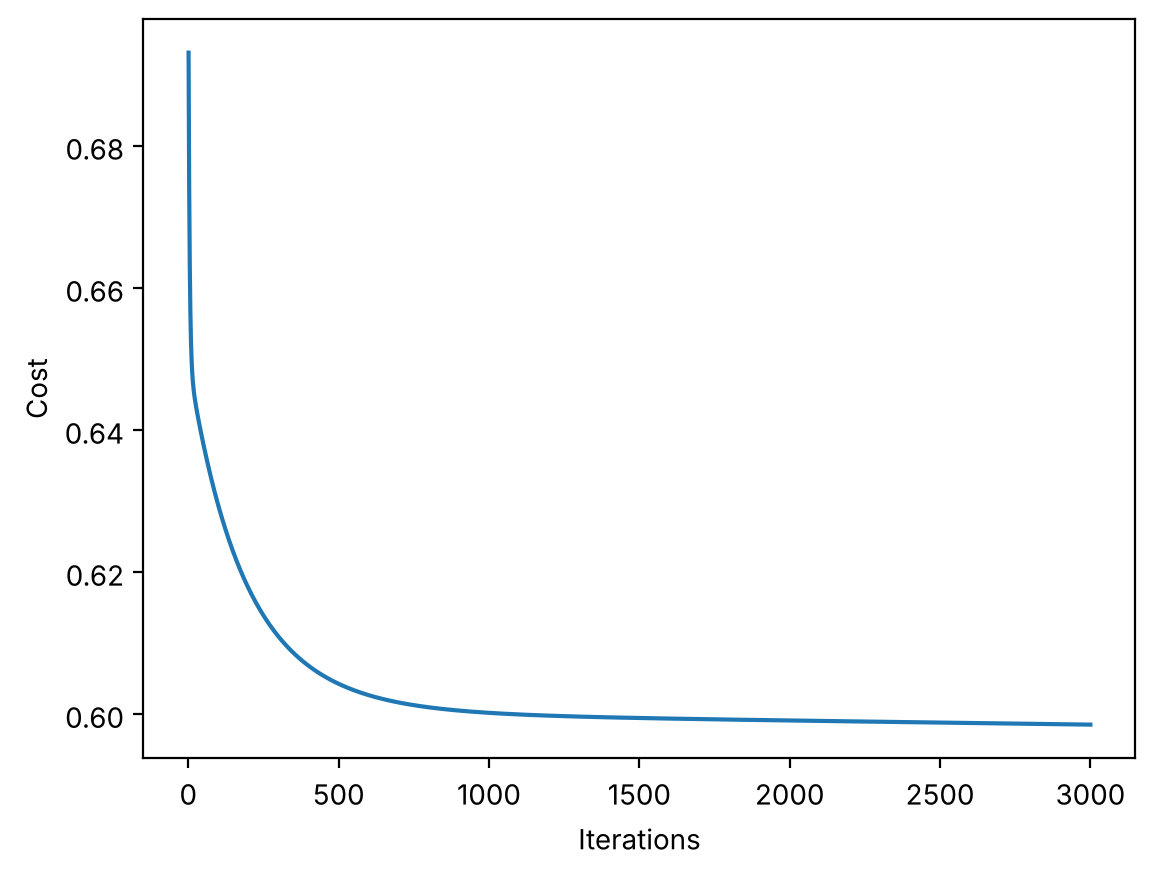

Final weights (Versicolor vs All): [ 0.08799678 -0.46643224  0.49856768]


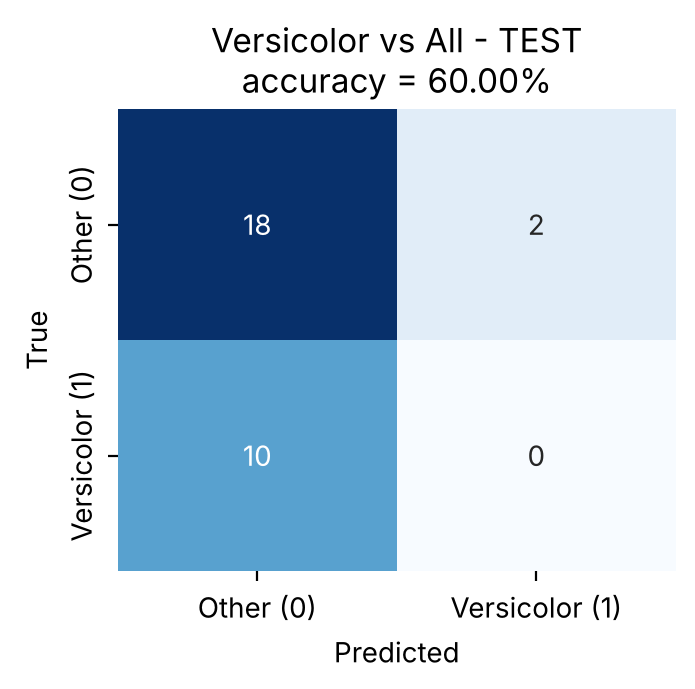

In [19]:
# Task 2 - Iris-Versicolor vs other classes
plot_one_vs_rest(1)
X_vc, y_vc = make_one_vs_rest(1)
Xtr_vc, Xte_vc, ytr_vc, yte_vc = train_test_split_np(X_vc, y_vc, 0.2, seed=42)
print("Train:", Xtr_vc.shape, "Test:", Xte_vc.shape)

W_vc = fit(0.01, 3000, Xtr_vc, ytr_vc)
print("Final weights (Versicolor vs All):", W_vc)
cm_vc, acc_vc = evaluate(Xte_vc, yte_vc, W_vc, "Versicolor vs All - TEST", ("Other (0)", "Versicolor (1)"))

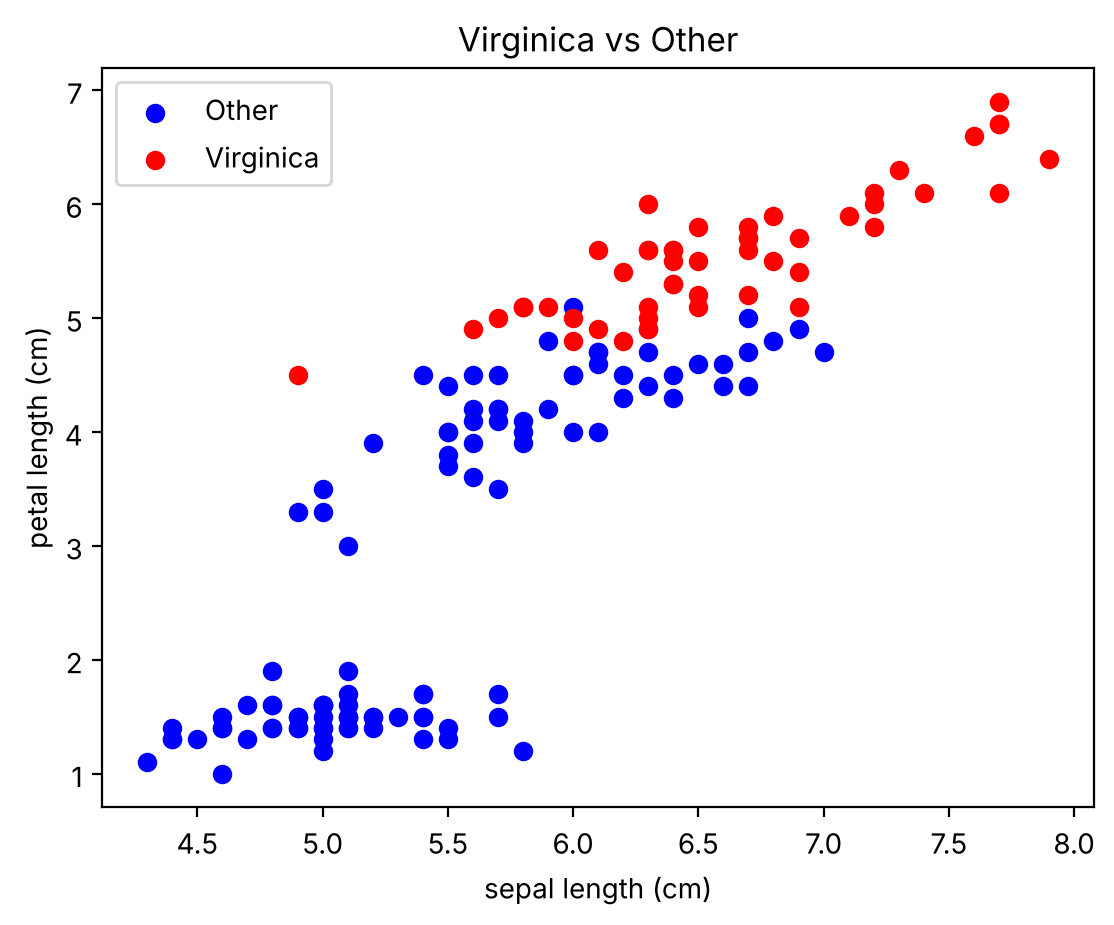

Train: (120, 3) Test: (30, 3)
iteration: 1 	 cost: 0.6931471805599435 	 weights: [-1.66666667e-03 -7.00833333e-03 -5.83333333e-05] 	
iteration: 101 	 cost: 0.5576639798375929 	 weights: [-0.08262354 -0.22450202  0.26088501] 	
iteration: 201 	 cost: 0.4878302143580723 	 weights: [-0.14249105 -0.36609845  0.4743369 ] 	
iteration: 301 	 cost: 0.4439669898715523 	 weights: [-0.19208397 -0.47964196  0.64230675] 	
iteration: 401 	 cost: 0.41405286046884415 	 weights: [-0.23471582 -0.5741936   0.78016478] 	
iteration: 501 	 cost: 0.39225953350427123 	 weights: [-0.27243364 -0.65534244  0.89721546] 	
iteration: 601 	 cost: 0.37554700615143183 	 weights: [-0.30654104 -0.72664948  0.99926155] 	
iteration: 701 	 cost: 0.3622101680400379 	 weights: [-0.33790116 -0.79047482  1.09007331] 	
iteration: 801 	 cost: 0.35122955555679636 	 weights: [-0.36710757 -0.84844274  1.17220084] 	
iteration: 901 	 cost: 0.3419616737294663 	 weights: [-0.39458249 -0.90170936  1.24743227] 	
iteration: 1001 	 cost: 0.

iteration: 1901 	 cost: 0.2904379690268911 	 weights: [-0.61695918 -1.29315901  1.79730138] 	
iteration: 2001 	 cost: 0.28725267340632765 	 weights: [-0.63607035 -1.32395422  1.84054448] 	
iteration: 2101 	 cost: 0.2842545890767575 	 weights: [-0.65481429 -1.35378008  1.88244463] 	
iteration: 2201 	 cost: 0.28142372178085523 	 weights: [-0.67321903 -1.38271272  1.92310986] 	
iteration: 2301 	 cost: 0.2787431256940742 	 weights: [-0.69130906 -1.41081859  1.96263423] 	
iteration: 2401 	 cost: 0.27619832178139864 	 weights: [-0.70910594 -1.43815612  2.00110014] 	
iteration: 2501 	 cost: 0.27377684623971454 	 weights: [-0.72662873 -1.46477692  2.03858023] 	
iteration: 2601 	 cost: 0.27146789611780375 	 weights: [-0.74389439 -1.49072684  2.07513888] 	
iteration: 2701 	 cost: 0.2692620484111658 	 weights: [-0.76091807 -1.51604686  2.11083348] 	
iteration: 2801 	 cost: 0.2671510353322809 	 weights: [-0.77771339 -1.54077372  2.14571537] 	
iteration: 2901 	 cost: 0.26512756297523427 	 weights: 

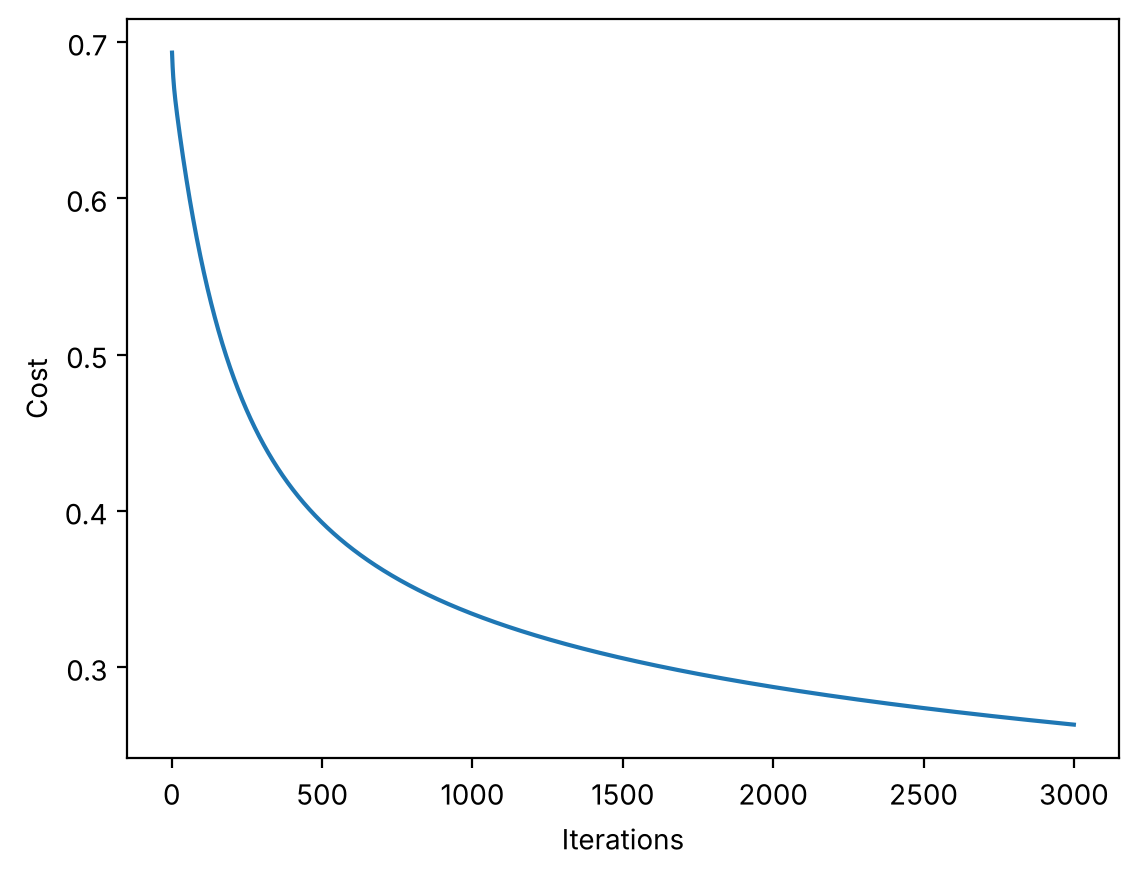

Final weights (Virginica vs All): [-0.8105042  -1.58834344  2.21289093]


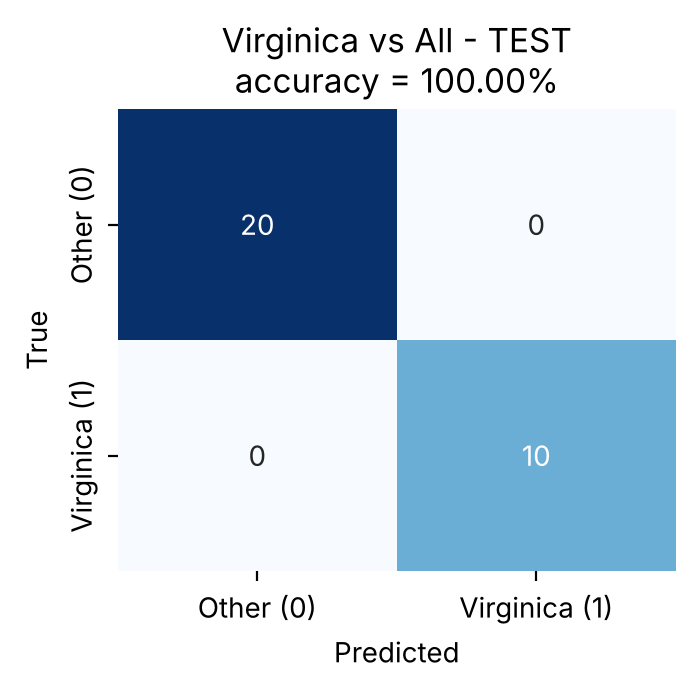

In [20]:
# Task 2 - Iris-Virginica vs other classes
plot_one_vs_rest(2)
X_vg, y_vg = make_one_vs_rest(2)
Xtr_vg, Xte_vg, ytr_vg, yte_vg = train_test_split_np(X_vg, y_vg, 0.2, seed=42)
print("Train:", Xtr_vg.shape, "Test:", Xte_vg.shape)

W_vg = fit(0.01, 3000, Xtr_vg, ytr_vg)
print("Final weights (Virginica vs All):", W_vg)
cm_vg, acc_vg = evaluate(Xte_vg, yte_vg, W_vg, "Virginica vs All - TEST", ("Other (0)", "Virginica (1)"))

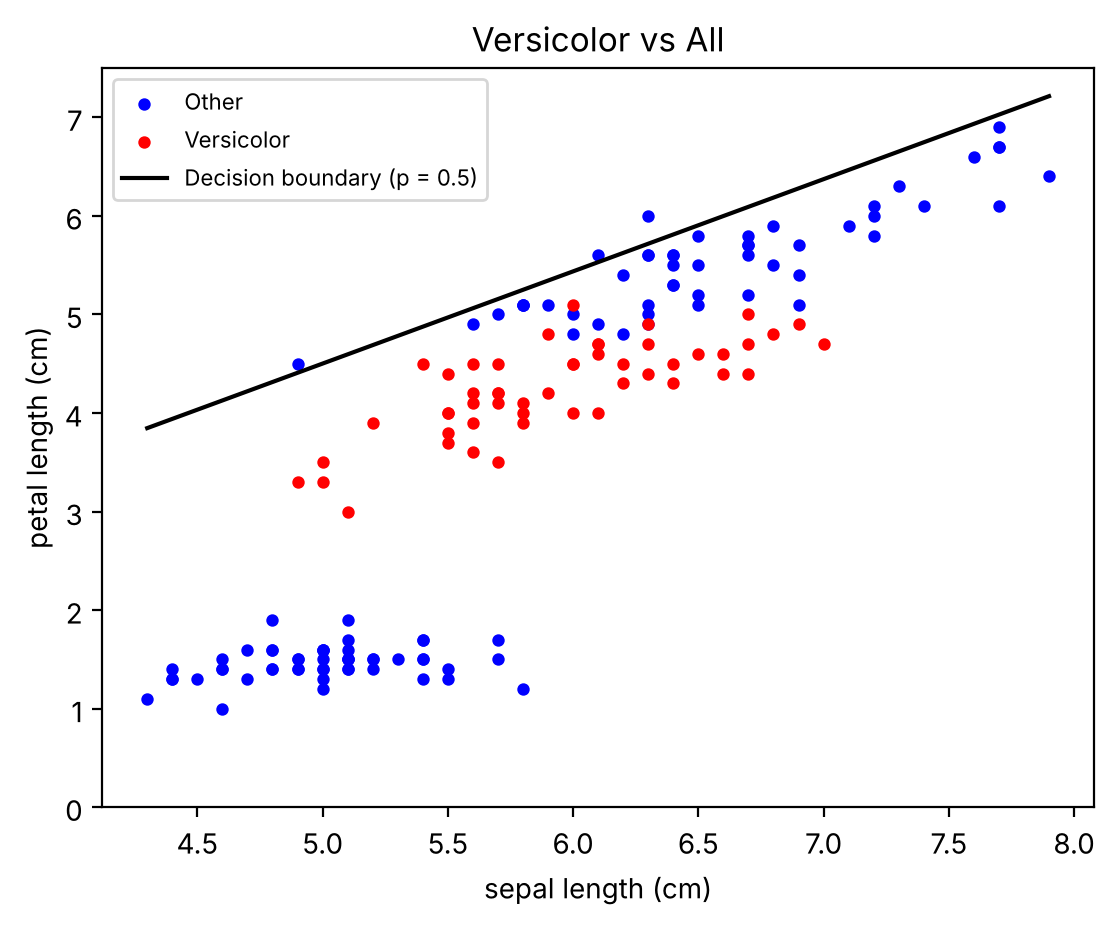

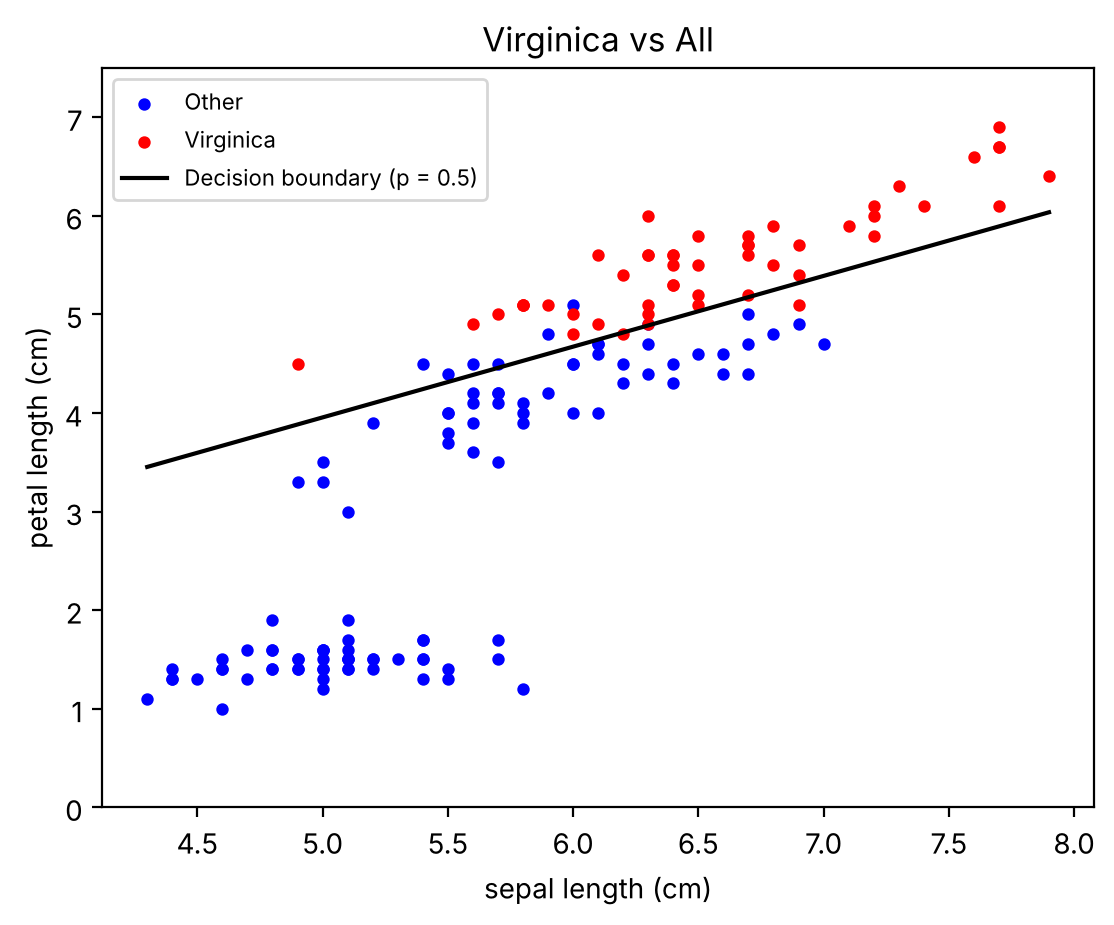

,Case,w0,w1 (sepal len),w2 (petal len),Test accuracy (%)
0,Setosa vs All,-0.498,-1.240,2.638,100.0
1,Versicolor vs All,0.088,-0.466,0.499,60.0
2,Virginica vs All,-0.811,-1.588,2.213,100.0


In [21]:
# Task 2 - comparison
def boundary_plot(X_all, y_all, W, name):
    xs = np.linspace(X_all[:, 1].min(), X_all[:, 1].max(), 50)
    plt.scatter(X_all[y_all == 0, 1], X_all[y_all == 0, 2], color='blue', s=12, label='Other')
    plt.scatter(X_all[y_all == 1, 1], X_all[y_all == 1, 2], color='red', s=12, label=name)
    plt.plot(xs, -(W[0] + W[1] * xs) / W[2], 'k', label='Decision boundary (p = 0.5)')
    plt.ylim(0, 7.5); plt.xlabel(feat1); plt.ylabel(feat2); plt.title(f"{name} vs All")
    plt.legend(loc='upper left', fontsize=8); plt.show()

boundary_plot(X_vc, y_vc, W_vc, 'Versicolor')
boundary_plot(X_vg, y_vg, W_vg, 'Virginica')

comparison = pd.DataFrame({
    "Case": ["Setosa vs All", "Versicolor vs All", "Virginica vs All"],
    "w0": [model_weights[0], W_vc[0], W_vg[0]],
    "w1 (sepal len)": [model_weights[1], W_vc[1], W_vg[1]],
    "w2 (petal len)": [model_weights[2], W_vc[2], W_vg[2]],
    "Test accuracy (%)": [acc_test * 100, acc_vc * 100, acc_vg * 100]})
comparison.round(3)

**Task 2 notes.**
* **Code changes.** Only the label mapping changes: `np.where(labels == target_class, 1, 0)` with `target_class = 1` (Versicolor) or `2` (Virginica). Each case gets its own stratified 80/20 split. Training (`fit`, α = 0.01, 3000 iterations) and evaluation are the same as in Task 1.
* **Virginica vs All works well (100% on this test split).** Virginica has the largest petals, so it sits at one end of the petal-length axis. A single straight line separates it from the rest. There is a small overlap with Versicolor, so with a different random split one or two test errors are possible.
* **Versicolor vs All performs badly.** Versicolor sits **in the middle**, between Setosa (small petals) and Virginica (large petals). To isolate it you would need two boundaries (a band), but logistic regression can only draw one straight line. The best it can do is lean towards predicting the majority class "Other" (2/3 of the data), so the test accuracy is only **60%**. The confusion matrix shows it predicts almost every flower as "Other": **all 10 Versicolor test samples are missed**, and 2 "Other" samples are wrongly called Versicolor. That is even below the 67% you would get by always guessing "Other". The boundary plot shows the line sitting above the whole Versicolor cloud. The weights are also small (about ±0.5), which shows the model cannot find a direction that separates the classes confidently.
* **Conclusion.** Performance depends on **class separability**, not on the algorithm or the amount of data: all three cases use the same features, model and hyper-parameters. Versicolor vs All would need non-linear features (for example $x^2$ terms, as in the previous tutorial) or a different model.

## Task 3 [40 marks]

In this tutorial, you were introduced to the parameter $\alpha$, also known as the learning rate. A fixed value of $0.01$ was chosen for our algorithm. Your task is to investigate the effect of selecting different values of $\alpha$ for the Iris-Setosa vs. All classifier. In your report, please cover the following aspects:

1. Experiment with different values of $\alpha$ (e.g., 0.0001, 0.1, 1, 100). Note that you may want to print the loss more frequently to observe the initial behavior of the algorithm when using different $\alpha$ values.

2. Run the code for each of the specified $\alpha$ values and record the performance of the network for each case.

3. Include a graphical representation of the cost versus epochs for each $\alpha$ value. Additionally, report the accuracy of the test data and provide confusion matrices for each $\alpha$ value.

4. In your own words, explain why the performance of the algorithm changes when using different $\alpha$ values. Discuss the effect of the learning rate on the gradient descent process, considering aspects like convergence speed, stability, and the risk of overshooting.


In [22]:
# Task 3
# fit_quiet() is the tutorial fit() without the plotting, returning the loss history too,
# and printing the loss at chosen iterations so the early behaviour is visible.

def fit_quiet(alpha, num_iter, X, y, print_at=(0, 1, 2, 5, 10, 50, 100, 500, 1000, 2999)):
    W = np.zeros(X.shape[1])
    loss_list = []
    with np.errstate(over='ignore'):          # very large alpha can overflow exp()
        for i in range(num_iter):
            Y = sigmoid(np.dot(X, W))
            W += alpha * (np.dot(X.T, (y - Y)) / y.size)
            loss = cost(Y, y)
            loss_list.append(loss)
            if i in print_at:
                print(f"  iteration {i + 1:5d}  cost = {loss:.5f}  weights = {np.round(W, 3)}")
    return W, loss_list

alphas = [0.0001, 0.01, 0.1, 1, 100]
num_iter = 3000
runs = {}
for a in alphas:
    print(f"alpha = {a}")
    W_a, loss_a = fit_quiet(a, num_iter, X_train, y_train)
    runs[a] = (W_a, loss_a)

alpha = 0.0001
  iteration     1  cost = 0.69315  weights = [0. 0. 0.]
  iteration     2  cost = 0.69279  weights = [0. 0. 0.]
  iteration     3  cost = 0.69243  weights = [0. 0. 0.]
  iteration     6  cost = 0.69136  weights = [0.    0.001 0.001]
  iteration    11  cost = 0.68959  weights = [0.    0.001 0.002]
  iteration    51  cost = 0.67620  weights = [0.001 0.006 0.007]
  iteration   101  cost = 0.66121  weights = [0.002 0.012 0.014]
  iteration   501  cost = 0.58764  weights = [0.005 0.044 0.057]
  iteration  1001  cost = 0.54983  weights = [0.006 0.062 0.096]
  iteration  3000  cost = 0.49848  weights = [-0.003  0.055  0.193]
alpha = 0.01
  iteration     1  cost = 0.69315  weights = [0.002 0.013 0.014]
  iteration     2  cost = 0.65937  weights = [0.003 0.023 0.027]
  iteration     3  cost = 0.63332  weights = [0.004 0.032 0.038]
  iteration     6  cost = 0.58448  weights = [0.006 0.051 0.067]
  iteration    11  cost = 0.54797  weights = [0.006 0.067 0.104]
  iteration    51  co

  iteration  1001  cost = -0.00000  weights = [-16.667 -40.083  92.375]
  iteration  3000  cost = -0.00000  weights = [-16.667 -40.083  92.375]


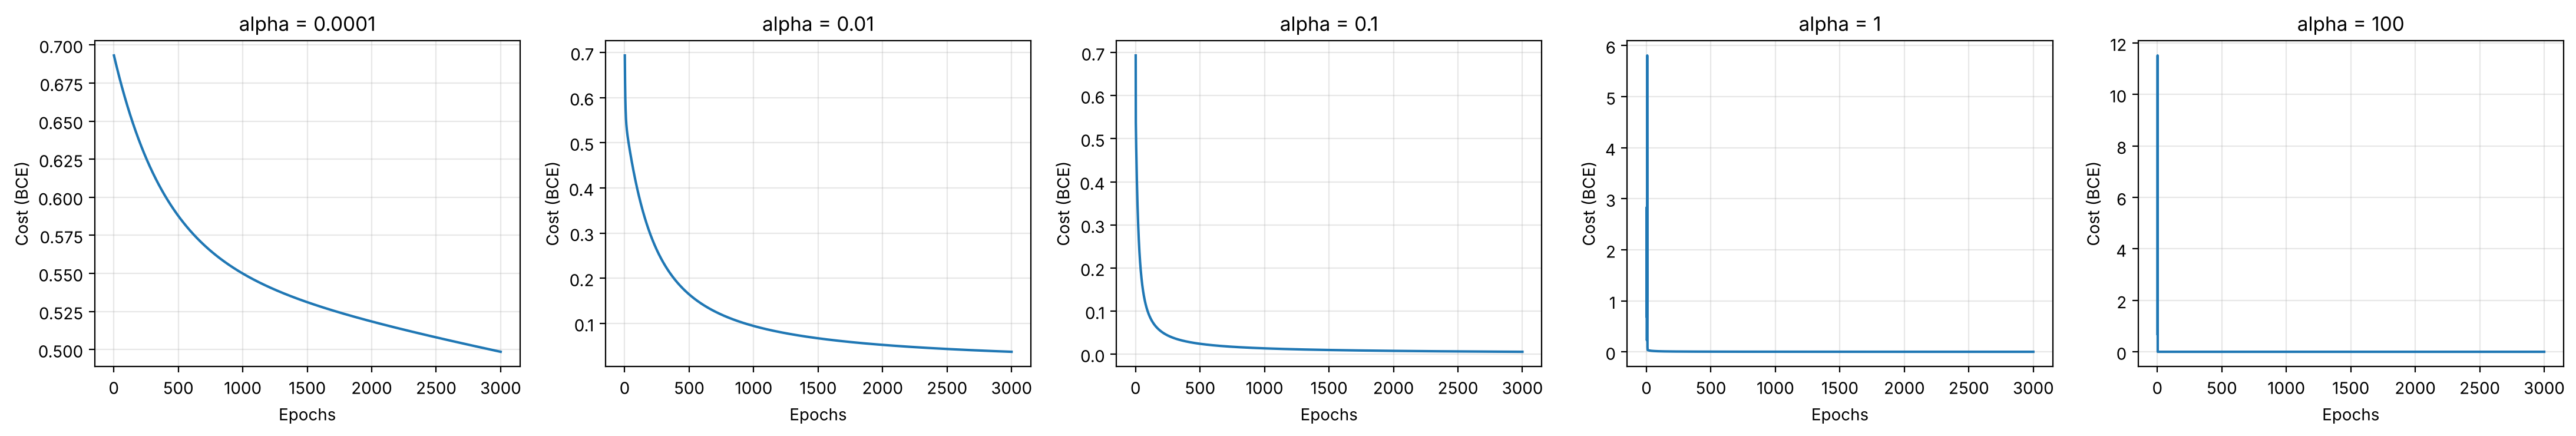

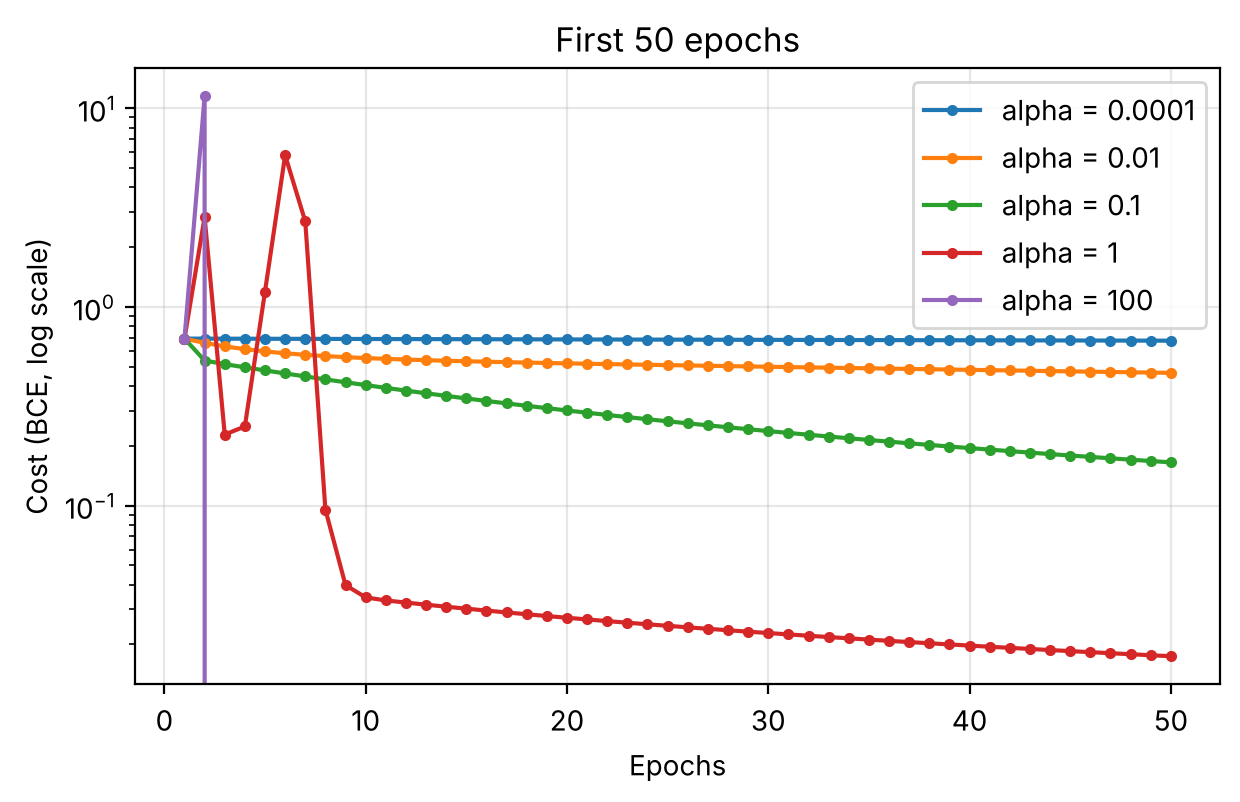

In [23]:
# Task 3 - cost vs epochs for each alpha
fig, axes = plt.subplots(1, len(alphas), figsize=(22, 3.8))
for ax, a in zip(axes, alphas):
    ax.plot(range(1, num_iter + 1), runs[a][1])
    ax.set_title(f"alpha = {a}")
    ax.set_xlabel("Epochs"); ax.set_ylabel("Cost (BCE)")
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# zoom on the first 50 epochs to see the start-up behaviour
plt.figure(figsize=(7, 4))
for a in alphas:
    plt.plot(range(1, 51), runs[a][1][:50], marker='.', label=f"alpha = {a}")
plt.yscale('log'); plt.xlabel("Epochs"); plt.ylabel("Cost (BCE, log scale)")
plt.title("First 50 epochs"); plt.legend(); plt.grid(alpha=0.3); plt.show()

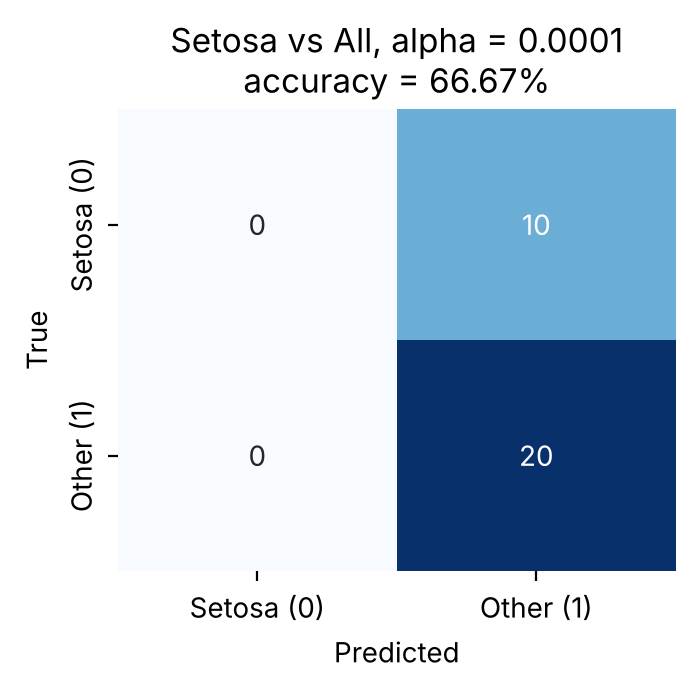

alpha = 0.0001: confusion matrix =
[[ 0. 10.]
 [ 0. 20.]]



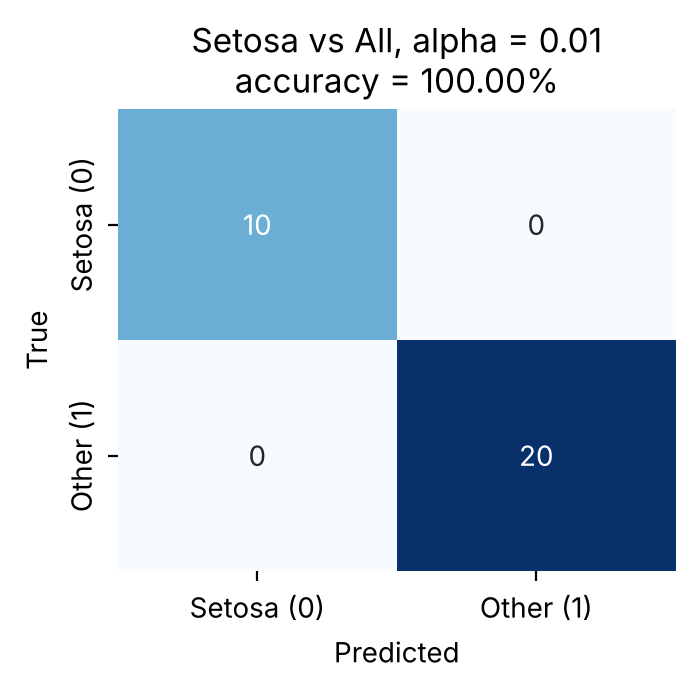

alpha = 0.01: confusion matrix =
[[10.  0.]
 [ 0. 20.]]



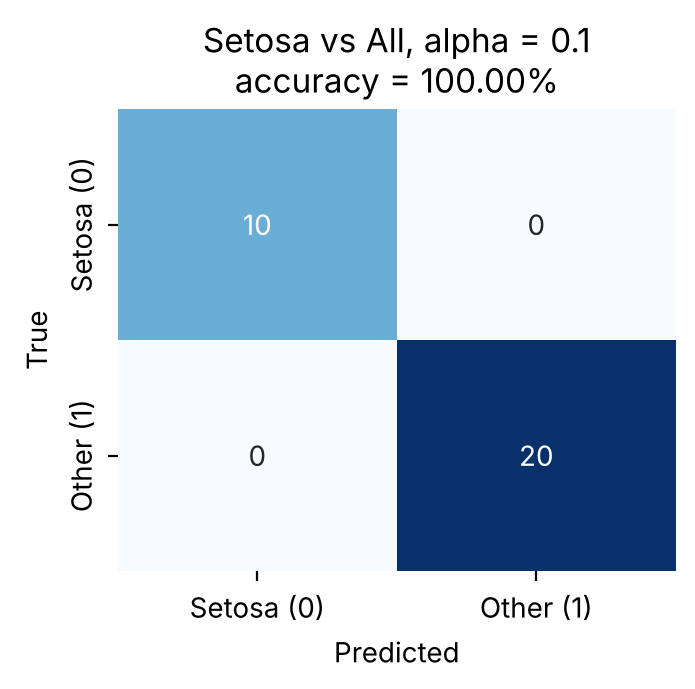

alpha = 0.1: confusion matrix =
[[10.  0.]
 [ 0. 20.]]



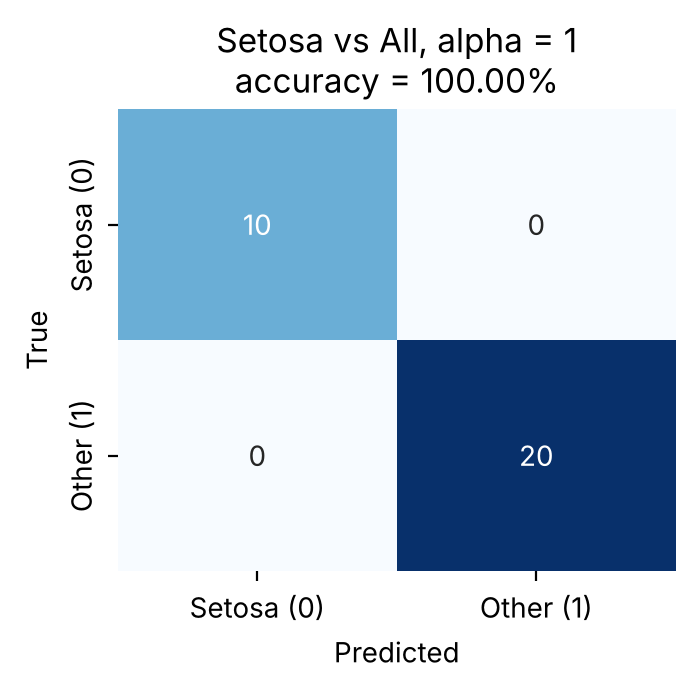

alpha = 1: confusion matrix =
[[10.  0.]
 [ 0. 20.]]



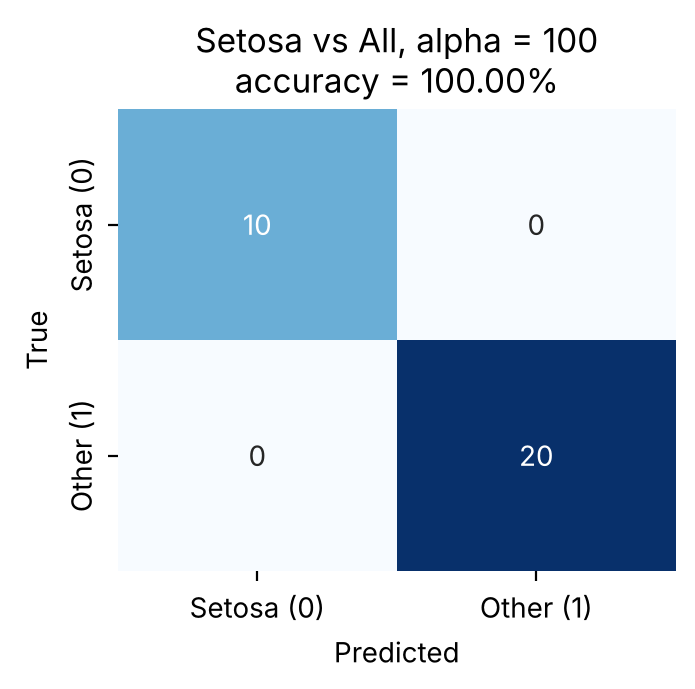

alpha = 100: confusion matrix =
[[10.  0.]
 [ 0. 20.]]



,alpha,initial cost,max cost,final cost,test accuracy (%),final weights
0,0.0001,0.693147,0.693147,4.984752e-01,66.666667,[-0.003 0.055 0.193]
1,0.0100,0.693147,0.693147,3.706603e-02,100.000000,[-0.498 -1.24 2.638]
2,0.1000,0.693147,0.693147,5.490937e-03,100.000000,[-0.916 -2.259 4.806]
3,1.0000,0.693147,5.807226,8.442976e-04,100.000000,[-1.399 -3.475 7.494]
4,100.0000,0.693147,11.512925,-1.087093e-15,100.000000,[-16.667 -40.083 92.375]


In [24]:
# Task 3 - test accuracy and confusion matrices for each alpha
task3 = []
for a in alphas:
    W_a, loss_a = runs[a]
    cm_a, acc_a = evaluate(X_test, y_test, W_a, f"Setosa vs All, alpha = {a}", ("Setosa (0)", "Other (1)"))
    print(f"alpha = {a}: confusion matrix =\n{cm_a}\n")
    task3.append([a, loss_a[0], max(loss_a), loss_a[-1], acc_a * 100, str(np.round(W_a, 3))])

pd.DataFrame(task3, columns=["alpha", "initial cost", "max cost", "final cost", "test accuracy (%)", "final weights"])

**Task 3 notes – effect of the learning rate α.**

The weight update is $\mathbf{w} \leftarrow \mathbf{w} + \alpha \cdot \frac{1}{N}X^T(y - \hat y)$, so α sets the size of each step down the cost surface.

* **α = 0.0001 (too small).** The steps are tiny, so after 3000 epochs the cost has only fallen from ln 2 ≈ 0.693 to about 0.50. The model is badly under-trained: every predicted probability is still above 0.5, so **every test flower is classified as "Other"**. The confusion matrix shows all 10 Setosa samples misclassified, giving 66.7% accuracy. It would need roughly 100× more epochs to reach the result of α = 0.01.
* **α = 0.01 (tutorial value) and α = 0.1.** The cost falls smoothly and both reach 100% test accuracy. α = 0.1 is about 10× faster: its cost at epoch 51 (0.163) matches α = 0.01 at epoch 501.
* **α = 1.** Here **overshooting is visible**: in the first ~6 epochs the cost jumps up and down, reaching about 5.8 (see the 50-epoch zoom plot), because the steps are big enough to cross the valley of the cost surface. Once the weights are in the right region it settles and ends with the lowest stable cost (about 0.0008). Because the data are linearly separable, the weights keep growing and the cost keeps creeping towards 0 without ever settling. That is not harmful for accuracy, but it shows the minimum is "at infinity" for separable data.
* **α = 100 (too large).** The first step multiplies the gradient by 100, so the weights jump to about [16.7, 126, 141]. Every point is then pushed to p ≈ 1, and the cost **shoots up to 11.5** on the next epoch. This is **overshooting**. The next step happens to land on weights that separate the data. From then on the sigmoid is saturated at exactly 0 or 1, so $(y - \hat y) = 0$, the gradient vanishes and the weights **freeze**. The test accuracy is 100% here only because the classes are easy to separate. The cost of "−0.0000" is not meaningful (it comes from the small `eps` in the log), and on a harder, non-separable problem a step this large would make the cost oscillate or diverge.

**Summary.** Too small α → stable but very slow convergence. Moderate α → fast and stable. Too large α → overshooting, oscillation or divergence. A good α is the largest value that still gives a smoothly decreasing cost curve.